In [1]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics.cluster import contingency_matrix 
from sklearn.metrics import adjusted_rand_score
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
#pd.set_option('display.max_rows', 200)
%matplotlib widget

In [3]:
import glob
path = "T:/BMS/new_Databackup/Jan/fiscas-validator/palma/pixel_size/reports"
result_files = glob.glob(path + "/results_summary_*.csv")
df = pd.read_csv(result_files[0])

In [4]:
for file in result_files[1:]:
    df = pd.concat([df, pd.read_csv(file)], ignore_index=True)
df

,ID,cell_types,output,use_perfect_registration,use_perfect_segmentation,teaching_imprecision,canvas_size,mic_spacing,ms_spacing,cell_density,...,m/z 0,STD m/z 0,m/z 1,STD m/z 1,m/z 2,STD m/z 2,m/z 3,STD m/z 3,FPR,ARI
0,cf04e16c-1858-4d59-8d7a-81c7214cdf9c,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.750000,3,0.2,...,0.004993,0.018465,0.001939,0.003562,0.005010,0.023908,0.012667,0.035979,0.0,0.961448
1,2e774518-ed71-4600-96af-b487710fb1bf,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,5,0.2,...,0.009719,0.018797,0.009210,0.012899,0.011662,0.020992,0.033510,0.066593,0.0,0.548348
2,87b2a192-a6e9-4e54-a316-06a8042590e1,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.727273,8,0.2,...,0.021659,0.032455,0.022698,0.031558,0.024315,0.055001,0.104064,0.197703,0.0,0.824222
3,205892eb-ad83-4d07-a87b-138f2c8d65e0,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,10,0.2,...,0.029900,0.044205,0.026262,0.035864,0.038146,0.089033,0.099163,0.184869,0.0,0.731023
4,17ad6604-f28d-4c01-92a2-b35cac34a228,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.722222,13,0.2,...,0.033542,0.052614,0.030198,0.043162,0.036999,0.063532,0.102680,0.204908,0.0,0.823144
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
92,c0c0f7c3-0d66-45ac-8177-d9ae603d6a49,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,15,0.2,...,0.046275,0.088519,0.056284,0.088810,0.038210,0.053080,0.129238,0.216805,0.0,0.958761
93,78bf99f6-db85-440b-a799-64366d9d769a,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.692308,18,0.2,...,0.046938,0.074806,0.054782,0.097428,0.065071,0.124123,0.163209,0.271740,0.0,0.940745
94,76f83e4a-9869-404f-aee4-22d1d8180f89,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,0.714286,20,0.2,...,0.065389,0.094136,0.071591,0.110822,0.085224,0.163794,0.181244,0.290532,0.0,0.807316
95,ff13b38d-0e87-45fe-b64a-8f4af83c286b,"['A', 'B']",/scratch/tmp/j_schw74/fiscas-validator/output/...,False,True,10,1000,1.000000,1,0.2,...,0.005277,0.007197,0.005499,0.008378,0.005773,0.010384,0.007546,0.020492,0.0,0.067099


In [5]:
df.columns

Index(['ID', 'cell_types', 'output', 'use_perfect_registration',
       'use_perfect_segmentation', 'teaching_imprecision', 'canvas_size',
       'mic_spacing', 'ms_spacing', 'cell_density',
       'max_cell_placement_iterations', 'rotation', 'scale', 'mass_list',
       'seed', 'plot', 'save_img', 'remove_ambiguous', 'cell_diameter',
       'texture', 'texture_path', 'texture_epsilon_add',
       'texture_epsilon_multiply', 'diffusion_total_time', 'diffusion_dt',
       'diffusion_coeff', 'diffusion_barrier_alpha',
       'diffusion_leaky_outer_boundary', 'MRE X', 'STD MRE X', 'MRE Y',
       'STD MRE Y', 'm/z 0', 'STD m/z 0', 'm/z 1', 'STD m/z 1', 'm/z 2',
       'STD m/z 2', 'm/z 3', 'STD m/z 3', 'FPR', 'ARI'],
      dtype='str')

In [6]:
mean_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].mean()
std_spacing = df.groupby('ms_spacing')[['ms_spacing', 'm/z 0', 'm/z 1', 'm/z 2', 'm/z 3', 'FPR', 'ARI']].std()

C:\Users\schwenzj\AppData\Local\Temp\ipykernel_22864\2364486807.py:7: UserWarning: marker is redundantly defined by the 'marker' keyword argument and the fmt string "o-" (-> marker='o'). The keyword argument will take precedence.
  plt.errorbar(mean_spacing['ms_spacing'], mean_spacing[mz], yerr=std_spacing[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)


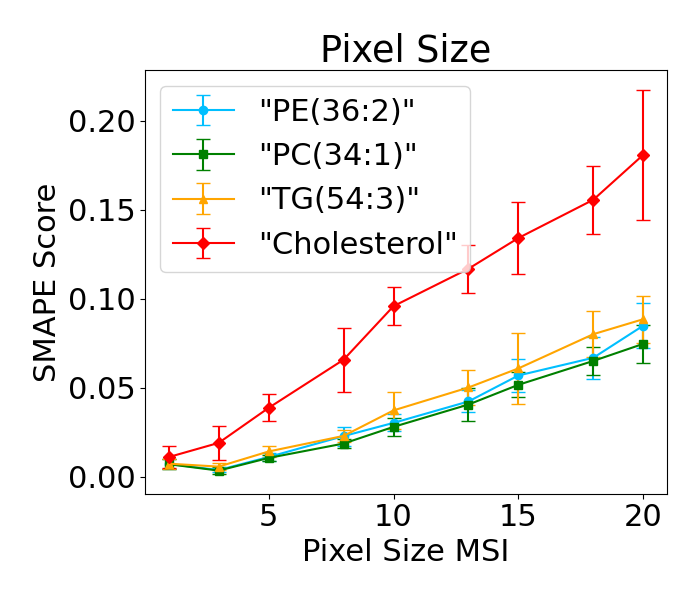

In [11]:
plt.rcParams.update({'font.size': 22})
colors = ['deepskyblue', 'green', 'orange', 'red']
markers = ['o', 's', '^', 'D']
labels = ['\"PE(36:2)\"', '\"PC(34:1)\"', '\"TG(54:3)\"', '\"Cholesterol\"']
plt.figure(figsize=(7,6))
for i, mz in enumerate(['m/z 0', 'm/z 1', 'm/z 2', 'm/z 3']):
    plt.errorbar(mean_spacing['ms_spacing'], mean_spacing[mz], yerr=std_spacing[mz], label=labels[i], color=colors[i], marker=markers[i], fmt='o-', capsize=5)
plt.xlabel('Pixel Size MSI')
plt.ylabel('SMAPE Score')
plt.title('Pixel Size')
plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_results.png", dpi=600)
plt.show()

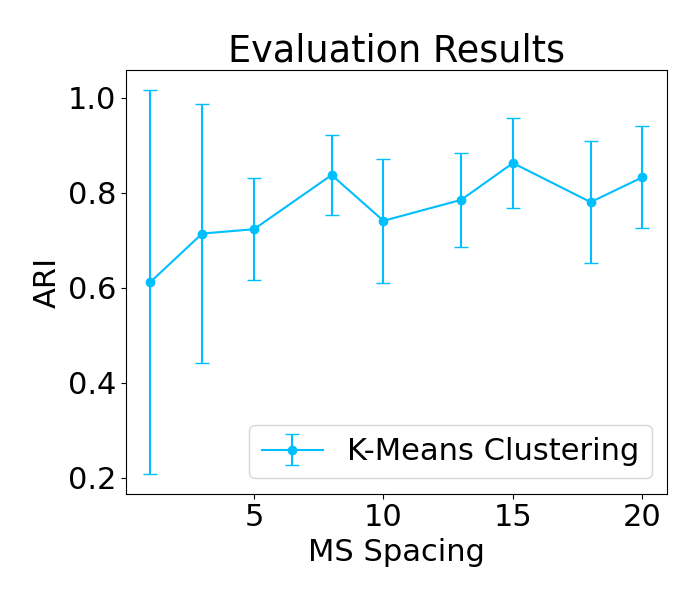

In [12]:
plt.figure(figsize=(7,6))
plt.errorbar(mean_spacing['ms_spacing'], mean_spacing['ARI'], yerr=std_spacing['ARI'], label='K-Means Clustering', color=colors[0], fmt='o-', capsize=5)
plt.xlabel('MS Spacing')
plt.ylabel('ARI')
plt.title('Evaluation Results')
plt.legend()
plt.tight_layout()
plt.savefig(path + "/evaluation/ms_spacing_ARI_results.png", dpi=600)
plt.show()